# 3. Modelling and related experiments
Initial/tuned baselines, tree tuning, forest importance, regularized stability, feature engineering/removal, two NN cases, threshold/ensemble comparisons and focused LR/NN tuning are retained.

**All 40 code cells were rerun sequentially in a fresh IPython process during the full project audit.** Model/feature results reproduce the original notebook; measured timings naturally differ. Tables show the latest execution. Original displayed tables are retained under results/historical.

Use raw training rows with fold-fitted pipelines for CV/search. Stored processed CSVs support fixed-split work. The economical alternatives are fixed to the originally reviewed configurations and must remain within 0.005 AP of the current training-CV winner. Timings are measured again, without silently replacing an alternative.

The sections form a development timeline. Statements that test evaluation is pending describe that earlier stage; Notebook 4 contains the completed frozen comparison. Timing numbers in the original explanatory prose are historical; use the refreshed tables for current measurements. No tuning against test outcomes is allowed.

Reading the saved results does not require rerunning training. Intentional reruns keep frozen model/test artifacts protected.


In [1]:
# Import the tools used in this notebook.
import os
for setting in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[setting] = '1'
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
# Locate the repository even before its local data has been downloaded.
from pathlib import Path
PROJECT = Path.cwd()
if not (PROJECT / '01_EDA.ipynb').exists():
    PROJECT = PROJECT / 'attrition'
assert (PROJECT / '01_EDA.ipynb').exists(), 'Open from the repository root or its parent.'

# Keep experimental reruns separate from the frozen comparison.
(PROJECT / 'artifacts/experimental_runs').mkdir(parents=True, exist_ok=True)


In [2]:
# Load raw splits without depending on another notebook's kernel.
manifest = json.loads((PROJECT / 'artifacts/manifest.json').read_text(encoding='utf-8'))
def load_split(name):
    import hashlib
    for prefix in ['X', 'y']:
        relative_path = f'data/splits/{prefix}_{name}.csv'
        actual_hash = hashlib.sha256((PROJECT / relative_path).read_bytes()).hexdigest()
        assert actual_hash == manifest['files'][relative_path], 'Split file changed: ' + relative_path
    predictors = pd.read_csv(PROJECT / f'data/splits/X_{name}.csv',
                             index_col='row_id', float_precision='round_trip')
    target = pd.read_csv(PROJECT / f'data/splits/y_{name}.csv', index_col='row_id')['attrition']
    assert predictors.index.equals(target.index) and predictors.index.is_unique
    assert target.isin([0, 1]).all() and len(target) == manifest['split_sizes'][name]
    assert {col: str(dtype) for col, dtype in predictors.dtypes.items()} == manifest['raw_dtypes']
    assert predictors.columns.tolist() == manifest['raw_predictors']
    return predictors, target
X_train, y_train = load_split('train')
X_val, y_val = load_split('validation')
print('Loaded training/validation rows:', len(X_train), len(X_val))

Loaded training/validation rows: 3000 1000


In [3]:
# Define column roles and ordinal category order.
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
num_cols = X_train.select_dtypes(include='number').columns.tolist()
ordinal_cols = ['education', 'travel_frequency']
nominal_cols = ['gender', 'marital_status', 'department', 'job_level']
education_order = ["Associate degree", "Bachelor's degree", "Master's degree", "Doctorate"]
travel_order = ['Never', 'Occasionally', 'Frequently']

In [4]:
# Build reusable preprocessing for scaled and unscaled models.
from sklearn.pipeline import Pipeline

# Each call creates a separate set of imputers, encoders, and scalers.
def make_preprocessor(scaled=True):
    numeric_steps = [('impute', SimpleImputer(strategy='median'))]
    ordinal_steps = [
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OrdinalEncoder(
            categories=[education_order, travel_order],
            handle_unknown='use_encoded_value', unknown_value=-1
        ))
    ]

    if scaled:
        numeric_steps.append(('scale', StandardScaler()))
        ordinal_steps.append(('scale', StandardScaler()))

    nominal_steps = [
        ('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]

    return ColumnTransformer([
        ('nominal', Pipeline(nominal_steps), nominal_cols),
        ('ordinal', Pipeline(ordinal_steps), ordinal_cols),
        ('numeric', Pipeline(numeric_steps), num_cols)
    ], verbose_feature_names_out=False).set_output(transform='pandas')

In [5]:
# Preserve full one-hot baselines and create reference-encoded versions.
def make_reference_preprocessor(scaled=True):
    return make_preprocessor(scaled).set_params(nominal__encode__drop='first')

In [6]:
# Create features inside the pipeline so each CV fold learns its own salary medians.
from sklearn.base import BaseEstimator, TransformerMixin

class EmployeeFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, kind='none', drop_job_level=False, drop_salary=False):
        self.kind = kind
        self.drop_job_level = drop_job_level
        self.drop_salary = drop_salary

    def fit(self, X, y=None):
        if self.kind == 'relative':
            self.salary_by_level_ = X.groupby('job_level')['monthly_salary'].median()
            self.salary_fallback_ = X['monthly_salary'].median()
        return self

    def transform(self, X):
        data = X.copy()
        if self.kind == 'interactions':
            dissatisfaction = 6 - data['job_satisfaction']
            data['overtime_dissatisfaction'] = data['overtime_hours'] * dissatisfaction
            data['combined_dissatisfaction'] = dissatisfaction * (6 - data['env_satisfaction'])
        elif self.kind == 'logs':
            data['monthly_salary'] = np.log1p(data['monthly_salary'])
            data['overtime_hours'] = np.log1p(data['overtime_hours'])
        elif self.kind == 'relative':
            level_median = data['job_level'].map(self.salary_by_level_)
            level_median = level_median.fillna(self.salary_fallback_)
            data['relative_salary'] = data['monthly_salary'] / level_median

        if self.drop_job_level:
            data = data.drop(columns='job_level')
        if self.drop_salary:
            data = data.drop(columns='monthly_salary')
        return data

In [7]:
# Load the exported variants for fixed-split work; CV below always uses raw X_train.
def load_processed(variant, split='train'):
    frame = pd.read_csv(PROJECT / f'data/preprocessed/{variant}/{split}.csv',
                        index_col='row_id', float_precision='round_trip')
    assert frame.columns.tolist() == manifest['feature_columns'][variant]
    expected_index = y_train.index if split == 'train' else y_val.index if split == 'validation' else load_split('test')[1].index
    assert frame.index.equals(expected_index) and np.isfinite(frame.to_numpy()).all()
    return frame
tree_full = {name: load_processed('unscaled_full_onehot', name)
             for name in ['train', 'validation']}
tree_reference = {name: load_processed('unscaled_reference', name)
                  for name in ['train', 'validation']}
X_train_pipeline_tree = tree_full['train']
X_train_reference = tree_reference['train']
X_train_reference_scaled = load_processed('scaled_reference')
feature_groups = {col: [c for c in X_train_reference if c.startswith(col + '_')]
                  for col in nominal_cols}
feature_groups.update({col: [col] for col in ordinal_cols + num_cols})
display(pd.read_csv(PROJECT / 'data/preprocessed/catalog.csv', index_col='Variant'))

,Features,Scaled,Reference encoding
Variant,,,
scaled_full_onehot,43,True,False
unscaled_full_onehot,43,False,False
scaled_reference,39,True,True
unscaled_reference,39,False,True
interactions_scaled,41,True,True
logs_scaled,39,True,True
relative_added_scaled,40,True,True
relative_no_job_scaled,35,True,True
relative_replace_both_scaled,34,True,True


### Step 9: baseline model comparison

Compare a dummy baseline, logistic regression, decision tree, and random forest using identical 5-fold stratified cross-validation on training data. Fit preprocessing inside each fold. Rank by average precision (AP, a precision–recall summary), and inspect recall, precision, F1, ROC-AUC, and accuracy. These first models use no class weighting or tuning. The dummy predicts the majority class and assigns training-prevalence probabilities. Undefined precision is reported as 0.


In [8]:
# Set up four baseline models and the same stratified folds for each.
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (make_scorer, precision_score, recall_score, f1_score,
                             average_precision_score, roc_auc_score, accuracy_score)

models = {
    'Dummy': Pipeline([('preprocess', make_preprocessor(False)),
                       ('model', DummyClassifier(strategy='prior'))]),
    'Logistic regression': Pipeline([('preprocess', make_preprocessor(True)),
        ('model', LogisticRegression(max_iter=2000, random_state=42))]),
    'Decision tree': Pipeline([('preprocess', make_preprocessor(False)),
        ('model', DecisionTreeClassifier(random_state=42))]),
    'Random forest': Pipeline([('preprocess', make_preprocessor(False)),
        ('model', RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=1))])
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'AP': 'average_precision', 'ROC_AUC': 'roc_auc', 'Accuracy': 'accuracy',
    'Precision': make_scorer(precision_score, zero_division=0),
    'Recall': make_scorer(recall_score, zero_division=0),
    'F1': make_scorer(f1_score, zero_division=0)
}


In [9]:
# Compare cross-validation scores using training data only.
# Each fold fits its own preprocessing; AP is our main ranking metric.
cv_results = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv,
                            scoring=scoring, n_jobs=1, error_score='raise')
    row = {'Model': name}
    for metric in scoring:
        row[metric] = scores['test_' + metric].mean()
    row['AP std'] = scores['test_AP'].std()
    cv_results.append(row)

cv_comparison = pd.DataFrame(cv_results).set_index('Model').sort_values('AP', ascending=False)
display(cv_comparison.round(3))


,AP,ROC_AUC,Accuracy,Precision,Recall,F1,AP std
Model,,,,,,,
Logistic regression,0.326,0.697,0.836,0.562,0.047,0.085,0.040
Random forest,0.307,0.686,0.838,0.583,0.016,0.032,0.027
Decision tree,0.179,0.538,0.736,0.223,0.245,0.233,0.012
Dummy,0.163,0.500,0.837,0.000,0.000,0.000,0.000


In [10]:
# Fit each model on all training rows and compare validation predictions.
# Keep default prediction thresholds and leave the test set unused.
validation_results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_val)
    probability = model.predict_proba(X_val)[:, 1]
    validation_results.append({
        'Model': name,
        'AP': average_precision_score(y_val, probability),
        'ROC_AUC': roc_auc_score(y_val, probability),
        'Accuracy': accuracy_score(y_val, prediction),
        'Precision': precision_score(y_val, prediction, zero_division=0),
        'Recall': recall_score(y_val, prediction, zero_division=0),
        'F1': f1_score(y_val, prediction, zero_division=0)
    })

validation_comparison = pd.DataFrame(validation_results).set_index('Model').sort_values('AP', ascending=False)
display(validation_comparison.round(3))


,AP,ROC_AUC,Accuracy,Precision,Recall,F1
Model,,,,,,
Logistic regression,0.292,0.693,0.830,0.286,0.024,0.045
Random forest,0.251,0.659,0.832,0.000,0.000,0.000
Decision tree,0.176,0.532,0.738,0.215,0.226,0.220
Dummy,0.164,0.500,0.836,0.000,0.000,0.000


Highest training CV AP: Logistic regression. Highest validation AP: Logistic regression. These are initial results; compare recall and precision before choosing a model or tuning its threshold. Test evaluation remains Step 10 after model selection.


### Step 9B: tuned baseline models

Select settings by average precision (AP) on the same 5-fold stratified CV using training data only. Preprocessing is fitted inside every fold. Include class weighting as an option. Compare selected models on validation data at default thresholds. Best CV scores are selection scores, not unbiased final performance estimates. The test set remains reserved.


In [11]:
# Create fresh pipelines; reuse 5-fold stratified CV and the scoring metrics.
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

lr_pipeline = Pipeline([('preprocess', make_preprocessor(True)),
    ('model', LogisticRegression(max_iter=5000, random_state=42))])
dt_pipeline = Pipeline([('preprocess', make_preprocessor(False)),
    ('model', DecisionTreeClassifier(random_state=42))])
rf_pipeline = Pipeline([('preprocess', make_preprocessor(False)),
    ('model', RandomForestClassifier(random_state=42, n_jobs=1))])


In [12]:
# Grid search valid logistic-regression settings; smaller C is stronger regularization.
lr_grid = [
    {'model__penalty': ['l2'], 'model__solver': ['lbfgs', 'liblinear', 'saga'],
     'model__C': [0.01, 0.1, 1], 'model__class_weight': [None, 'balanced']},
    {'model__penalty': ['l1'], 'model__solver': ['liblinear', 'saga'],
     'model__C': [0.01, 0.1, 1], 'model__class_weight': [None, 'balanced']},
    {'model__penalty': ['elasticnet'], 'model__solver': ['saga'],
     'model__C': [0.01, 0.1, 1], 'model__l1_ratio': [0.25, 0.75],
     'model__class_weight': [None, 'balanced']}
]

lr_search = GridSearchCV(lr_pipeline, lr_grid, cv=cv, scoring=scoring,
                         refit='AP', n_jobs=2, error_score='raise')
lr_search.fit(X_train, y_train)
print('Best logistic regression:', lr_search.best_params_)
print('CV average precision:', round(lr_search.best_score_, 3))


Best logistic regression: {'model__C': 0.1, 'model__class_weight': None, 'model__l1_ratio': 0.25, 'model__penalty': 'elasticnet', 'model__solver': 'saga'}
CV average precision: 0.33


In [13]:
# Tune 24 decision-tree settings to control complexity and test class weighting.
dt_grid = {
    'model__max_depth': [3, 5, 8, None],
    'model__min_samples_leaf': [5, 20, 50],
    'model__class_weight': [None, 'balanced']
}
dt_search = GridSearchCV(dt_pipeline, dt_grid, cv=cv, scoring=scoring,
                         refit='AP', n_jobs=2, error_score='raise')
dt_search.fit(X_train, y_train)
print('Best decision tree:', dt_search.best_params_)
print('CV average precision:', round(dt_search.best_score_, 3))


Best decision tree: {'model__class_weight': None, 'model__max_depth': 3, 'model__min_samples_leaf': 50}
CV average precision: 0.254


In [14]:
# Randomly sample 16 forest settings with a fixed seed for reproducibility.
rf_parameters = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [5, 10, None],
    'model__min_samples_leaf': [1, 5, 15],
    'model__max_features': ['sqrt', 0.5],
    'model__class_weight': [None, 'balanced_subsample']
}
rf_search = RandomizedSearchCV(
    rf_pipeline, rf_parameters, n_iter=16, cv=cv, scoring=scoring,
    refit='AP', random_state=42, n_jobs=2, error_score='raise'
)
rf_search.fit(X_train, y_train)
print('Best random forest:', rf_search.best_params_)
print('CV average precision:', round(rf_search.best_score_, 3))


Best random forest: {'model__n_estimators': 200, 'model__min_samples_leaf': 15, 'model__max_features': 0.5, 'model__max_depth': 5, 'model__class_weight': 'balanced_subsample'}
CV average precision: 0.32


In [15]:
# Compare tuned models on validation data using the default prediction threshold.
searches = {'Logistic regression': lr_search, 'Decision tree': dt_search,
            'Random forest': rf_search}
tuning_results = []
for name, search in searches.items():
    prediction = search.predict(X_val)
    probability = search.predict_proba(X_val)[:, 1]
    tuning_results.append({
        'Model': name, 'CV AP': search.best_score_,
        'CV AP std': search.cv_results_['std_test_AP'][search.best_index_],
        'Validation AP': average_precision_score(y_val, probability),
        'ROC_AUC': roc_auc_score(y_val, probability),
        'Accuracy': accuracy_score(y_val, prediction),
        'Precision': precision_score(y_val, prediction, zero_division=0),
        'Recall': recall_score(y_val, prediction, zero_division=0),
        'F1': f1_score(y_val, prediction, zero_division=0)
    })

tuned_comparison = pd.DataFrame(tuning_results).set_index('Model')
tuned_comparison = tuned_comparison.sort_values('Validation AP', ascending=False)
display(tuned_comparison.round(3))

# Check whether tuning improves validation average precision over each baseline.
ap_comparison = validation_comparison[['AP']].rename(columns={'AP': 'Baseline AP'})
ap_comparison['Tuned AP'] = tuned_comparison['Validation AP']
display(ap_comparison.round(3))


,CV AP,CV AP std,Validation AP,ROC_AUC,Accuracy,Precision,Recall,F1
Model,,,,,,,,
Logistic regression,0.330,0.041,0.297,0.699,0.830,0.200,0.012,0.023
Random forest,0.320,0.015,0.266,0.678,0.656,0.243,0.518,0.331
Decision tree,0.254,0.021,0.245,0.655,0.827,0.235,0.024,0.044


,Baseline AP,Tuned AP
Model,,
Logistic regression,0.292,0.297
Random forest,0.251,0.266
Decision tree,0.176,0.245
Dummy,0.164,NaN


Tuning complete. Search objects retain fitted best pipelines in `best_estimator_`. Inspect validation precision and recall before selecting a model or tuning its threshold. No test predictions were made.


### Feature assessment: baseline archive and reference encoding

Treat all initial and tuned models above as baselines. Create new reference-category preprocessors and assess training predictors only. Keep earlier models and feature values unchanged. Dropping a category removes exact dummy-variable dependence; it does not establish that the underlying predictor is unimportant.


In [16]:
# Keep all previous models and results as baselines for later comparisons.
baseline_models = models.copy()
baseline_tuned_models = {name: search.best_estimator_ for name, search in searches.items()}
baseline_cv_results = cv_comparison.copy()
baseline_validation_results = validation_comparison.copy()
baseline_tuned_results = tuned_comparison.copy()
print('Saved initial and tuned models as baselines.')


Saved initial and tuned models as baselines.


In [17]:
# Compare L2 logistic regression with and without the flagged feature groups.
# Keep C=1 and all other model settings fixed to isolate the feature-removal effect.
def make_ridge_model(excluded):
    preprocessor = make_reference_preprocessor(True)
    preprocessor.transformers = [
        (name, steps, [col for col in columns if col not in excluded])
        for name, steps, columns in preprocessor.transformers
    ]
    return Pipeline([
        ('preprocess', preprocessor),
        ('model', LogisticRegression(penalty='l2', C=1, solver='lbfgs',
                                     max_iter=5000, random_state=42))
    ])

feature_sets = {
    'All features': [],
    'Without salary': ['monthly_salary'],
    'Without job level': ['job_level'],
    'Without both': ['monthly_salary', 'job_level']
}
ridge_models = {}
stability_rows = []
for name, excluded in feature_sets.items():
    model = make_ridge_model(excluded)
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring,
                            n_jobs=1, error_score='raise')
    model.fit(X_train, y_train)
    ridge_models[name] = model
    prediction = model.predict(X_val)
    probability = model.predict_proba(X_val)[:, 1]
    stability_rows.append({
        'Feature set': name, 'CV AP': scores['test_AP'].mean(),
        'CV ROC-AUC': scores['test_ROC_AUC'].mean(),
        'Validation AP': average_precision_score(y_val, probability),
        'Validation ROC-AUC': roc_auc_score(y_val, probability),
        'Accuracy': accuracy_score(y_val, prediction),
        'Recall': recall_score(y_val, prediction, zero_division=0),
        'F1': f1_score(y_val, prediction, zero_division=0)
    })

ridge_stability = pd.DataFrame(stability_rows).set_index('Feature set')
display(ridge_stability.round(3))


,CV AP,CV ROC-AUC,Validation AP,Validation ROC-AUC,Accuracy,Recall,F1
Feature set,,,,,,,
All features,0.326,0.698,0.292,0.693,0.830,0.024,0.045
Without salary,0.326,0.698,0.294,0.693,0.829,0.024,0.045
Without job level,0.328,0.697,0.292,0.695,0.829,0.018,0.034
Without both,0.318,0.689,0.280,0.687,0.833,0.012,0.023


In [18]:
# Fit a reference-encoded forest using the earlier tuned forest settings.
rf_importance_model = Pipeline([
    ('preprocess', make_reference_preprocessor(False)),
    ('model', RandomForestClassifier(random_state=42, n_jobs=1))
]).set_params(**rf_search.best_params_)
rf_importance_model.fit(X_train, y_train)

# Sum encoded-column impurity importances back to the original predictors.
forest_columns = rf_importance_model.named_steps['preprocess'].get_feature_names_out()
encoded_importance = pd.Series(
    rf_importance_model.named_steps['model'].feature_importances_, index=forest_columns
)
forest_importance = pd.Series({
    feature: encoded_importance[columns].sum()
    for feature, columns in feature_groups.items()
}, name='Impurity importance').sort_values(ascending=False)
display(forest_importance.head(10).round(4))


job_satisfaction      0.2264
env_satisfaction      0.1632
monthly_salary        0.0971
overtime_hours        0.0658
salary_hike_pct       0.0603
job_involvement       0.0452
commute_distance      0.0413
relationship_score    0.0380
age                   0.0307
leave_days            0.0294
Name: Impurity importance, dtype: float64

In [19]:
# Cross-check forest importance by shuffling original validation predictors.
# This shuffles each categorical predictor as a whole, not separate dummy columns.
from sklearn.inspection import permutation_importance

permutation = permutation_importance(
    rf_importance_model, X_val, y_val, scoring='average_precision',
    n_repeats=5, random_state=42, n_jobs=1
)
permutation_summary = pd.DataFrame({
    'AP decrease': permutation.importances_mean,
    'Repeat std': permutation.importances_std
}, index=X_val.columns).sort_values('AP decrease', ascending=False)
display(permutation_summary.head(10).round(4))


,AP decrease,Repeat std
job_satisfaction,0.0187,0.0073
monthly_salary,0.0141,0.0059
env_satisfaction,0.0098,0.0186
salary_hike_pct,0.0094,0.0046
relationship_score,0.0029,0.0040
total_work_years,0.0021,0.0008
education,0.0020,0.0011
work_life_balance,0.0019,0.0029
overtime_hours,0.0008,0.0023
late_count,0.0008,0.0012


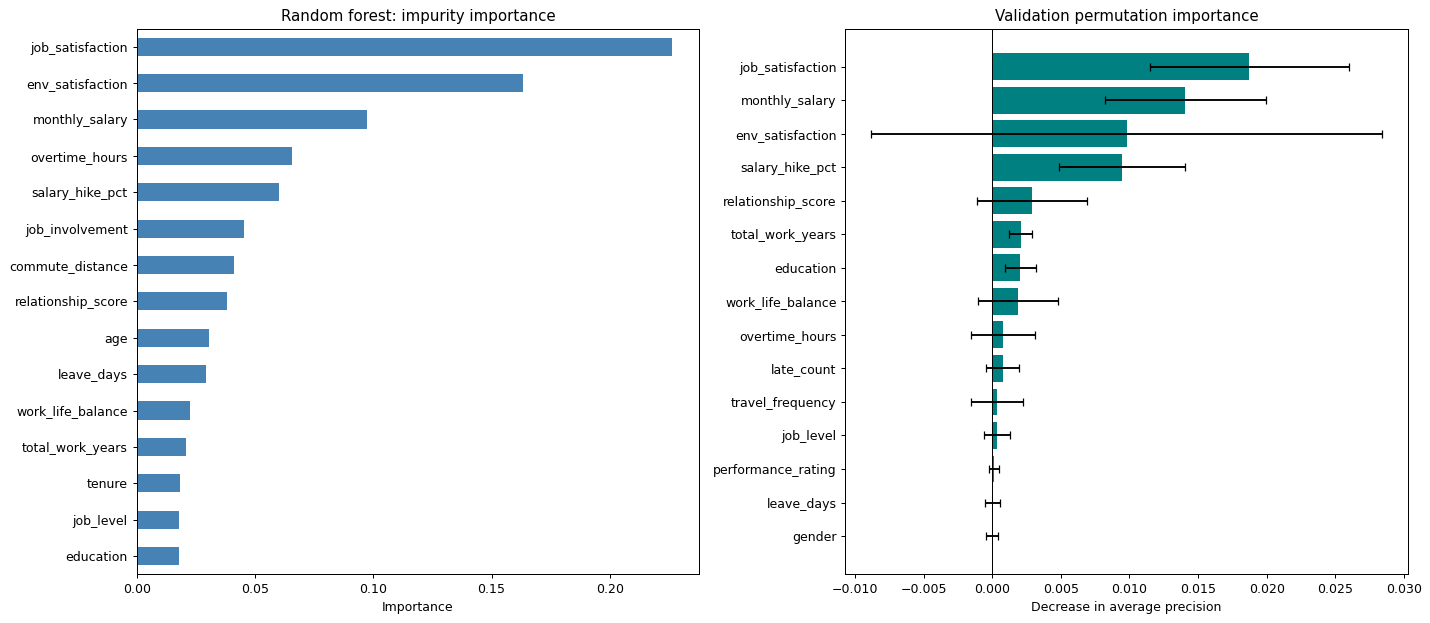

In [20]:
# Plot the top 15 predictors using both importance measures.
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
forest_importance.head(15).sort_values().plot.barh(ax=axes[0], color='steelblue')
axes[0].set(title='Random forest: impurity importance', xlabel='Importance', ylabel='')

plot_data = permutation_summary.head(15).sort_values('AP decrease')
axes[1].barh(plot_data.index, plot_data['AP decrease'],
             xerr=plot_data['Repeat std'], color='teal', capsize=3)
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set(title='Validation permutation importance', xlabel='Decrease in average precision', ylabel='')
plt.tight_layout()
plt.show()


Interpretation: assess predictive changes using CV and validation results, not VIF alone. Impurity importance can favor continuous or high-cardinality predictors. Permutation importance can understate redundant predictors because related features retain similar information; repeat standard deviations show shuffle variability, not confidence intervals. Neither importance nor an omnibus p-value establishes causation. No features are removed automatically.

References: [GVIF documentation](https://www.rdocumentation.org/packages/car/versions/3.1-5/topics/vif), [scikit-learn importance limitations](https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance_multicollinear.html).


### Feature engineering experiments

Test dissatisfaction interactions, log1p transformations, and salary relative to the training median for each job level. Compare relative salary with the original salary/job-level features retained or removed. Fit all learned transformations inside the CV pipeline; keep L2 logistic settings and folds fixed. Missing engineered values are imputed by the numerical pipeline. Missing or unseen job levels use the training-wide salary median. Test data remains reserved.


In [21]:
# Use identical L2 logistic settings for every experiment.
def make_feature_model(kind='none', drop_job_level=False, drop_salary=False):
    added_columns = {
        'none': [], 'logs': [],
        'interactions': ['overtime_dissatisfaction', 'combined_dissatisfaction'],
        'relative': ['relative_salary']
    }[kind]
    excluded = []
    if drop_job_level:
        excluded.append('job_level')
    if drop_salary:
        excluded.append('monthly_salary')

    preprocessor = make_reference_preprocessor(True)
    preprocessor.transformers = [
        (name, steps, [col for col in columns if col not in excluded]
         + (added_columns if name == 'numeric' else []))
        for name, steps, columns in preprocessor.transformers
    ]
    return Pipeline([
        ('features', EmployeeFeatures(kind, drop_job_level, drop_salary)),
        ('preprocess', preprocessor),
        ('model', LogisticRegression(penalty='l2', C=1, solver='lbfgs',
                                     max_iter=5000, random_state=42))
    ])

feature_models = {
    'L2 baseline': make_feature_model(),
    'Dissatisfaction interactions': make_feature_model('interactions'),
    'Log salary and overtime': make_feature_model('logs'),
    'Relative salary added': make_feature_model('relative'),
    'Relative salary, no job level': make_feature_model('relative', drop_job_level=True),
    'Relative salary replaces both': make_feature_model('relative', drop_job_level=True, drop_salary=True)
}


In [22]:
# Compare each feature experiment using the same folds and validation data.
feature_results = []
feature_cv_scores = {}
for name, model in feature_models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring,
                            n_jobs=1, error_score='raise')
    feature_cv_scores[name] = scores['test_AP']
    model.fit(X_train, y_train)
    prediction = model.predict(X_val)
    probability = model.predict_proba(X_val)[:, 1]
    feature_results.append({
        'Experiment': name, 'CV AP': scores['test_AP'].mean(),
        'CV AP std': scores['test_AP'].std(),
        'Validation AP': average_precision_score(y_val, probability),
        'Validation ROC-AUC': roc_auc_score(y_val, probability),
        'Accuracy': accuracy_score(y_val, prediction),
        'Precision': precision_score(y_val, prediction, zero_division=0),
        'Recall': recall_score(y_val, prediction, zero_division=0),
        'F1': f1_score(y_val, prediction, zero_division=0)
    })

feature_comparison = pd.DataFrame(feature_results).set_index('Experiment')
feature_comparison['CV AP change'] = feature_comparison['CV AP'] - feature_comparison.loc['L2 baseline', 'CV AP']
feature_comparison['Validation AP change'] = feature_comparison['Validation AP'] - feature_comparison.loc['L2 baseline', 'Validation AP']
display(feature_comparison.sort_values('CV AP', ascending=False).round(4))


,CV AP,CV AP std,Validation AP,Validation ROC-AUC,Accuracy,Precision,Recall,F1,CV AP change,Validation AP change
Experiment,,,,,,,,,,
Dissatisfaction interactions,0.3273,0.0375,0.2888,0.6929,0.826,0.0833,0.0061,0.0114,0.0011,-0.0028
"Relative salary, no job level",0.3268,0.0359,0.2926,0.6955,0.828,0.2143,0.0183,0.0337,0.0006,0.0010
Relative salary added,0.3262,0.0398,0.2913,0.6928,0.830,0.2857,0.0244,0.0449,0.0000,-0.0003
L2 baseline,0.3262,0.0400,0.2916,0.6929,0.830,0.2857,0.0244,0.0449,0.0000,0.0000
Log salary and overtime,0.3226,0.0372,0.2885,0.6915,0.827,0.0909,0.0061,0.0114,-0.0035,-0.0031
Relative salary replaces both,0.3169,0.0316,0.2798,0.6868,0.833,0.2857,0.0122,0.0234,-0.0093,-0.0118


C:\Users\heman\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:452: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
C:\Users\heman\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:452: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
C:\Users\heman\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:452: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
C:\Users\heman\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:452: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_r

In [23]:
# Check whether each experiment improves AP consistently across the five folds.
fold_changes = pd.DataFrame({
    name: values - feature_cv_scores['L2 baseline']
    for name, values in feature_cv_scores.items() if name != 'L2 baseline'
}, index=['Fold 1', 'Fold 2', 'Fold 3', 'Fold 4', 'Fold 5']).T
display(fold_changes.round(4))


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
Dissatisfaction interactions,-0.0030,0.0008,0.0078,-0.0036,0.0035
Log salary and overtime,-0.0046,-0.0092,0.0046,-0.0116,0.0031
Relative salary added,-0.0003,-0.0008,-0.0010,0.0006,0.0015
"Relative salary, no job level",0.0005,-0.0103,0.0079,0.0010,0.0039
Relative salary replaces both,-0.0166,-0.0277,-0.0036,0.0021,-0.0005


**Feature-engineering conclusion:** interactions changed CV AP by only +0.0011 but reduced validation AP by 0.0028. Relative salary without job level gave a tiny validation gain of 0.0010 with mixed fold results. Logs and replacing both salary and job level performed worse. Keep the original predictors as the main baseline; do not combine changes without clearer evidence.

### Feature removal experiments

**Purpose:** check whether fewer predictors simplify L2 logistic regression without losing predictive ability. Remove each of the 25 original predictors individually, including whole dummy groups. Keep model settings and five stratified training folds fixed.

Shortlist up to three removals with positive mean AP change and gains in at least three folds, then check combinations. This is exploratory screening, not a significance test. Validate only the shortlist. Preprocessing stays inside each fold and the test set remains reserved.

In [24]:
# Remove whole predictors, keeping each encoder aligned with retained columns.
def make_ablation_model(excluded):
    preprocessor = make_reference_preprocessor(True)
    preprocessor.transformers = [
        (name, steps, [col for col in columns if col not in excluded])
        for name, steps, columns in preprocessor.transformers
    ]
    orders = {'education': education_order, 'travel_frequency': travel_order}
    preprocessor.set_params(ordinal__encode__categories=[
        orders[col] for col in ordinal_cols if col not in excluded
    ])
    return Pipeline([
        ('preprocess', preprocessor),
        ('model', LogisticRegression(penalty='l2', C=1, solver='lbfgs',
                                     max_iter=5000, random_state=42))
    ])

# Test all predictors, then each of the 25 single-feature removals.
ablation_folds = {}
ablation_rows = []
for feature in [None] + X_train.columns.tolist():
    excluded = [] if feature is None else [feature]
    name = 'All features' if feature is None else feature
    scores = cross_validate(make_ablation_model(excluded), X_train, y_train,
                            cv=cv, scoring=scoring, n_jobs=1, error_score='raise')
    ablation_folds[name] = scores['test_AP']
    ablation_rows.append({
        'Removed feature': name, 'CV AP': scores['test_AP'].mean(),
        'CV AP std': scores['test_AP'].std(),
        'CV ROC-AUC': scores['test_ROC_AUC'].mean()
    })

ablation_results = pd.DataFrame(ablation_rows).set_index('Removed feature')
ablation_results['AP change'] = ablation_results['CV AP'] - ablation_results.loc['All features', 'CV AP']
ablation_results['Folds improved'] = [
    int((ablation_folds[name] > ablation_folds['All features']).sum())
    for name in ablation_results.index
]
display(ablation_results.sort_values('CV AP', ascending=False).round(4))


,CV AP,CV AP std,CV ROC-AUC,AP change,Folds improved
Removed feature,,,,,
gender,0.3288,0.0397,0.6990,0.0026,5
work_life_balance,0.3282,0.0402,0.6961,0.0021,3
num_companies,0.3282,0.0415,0.6996,0.0021,3
tenure,0.3282,0.0444,0.6969,0.0020,3
job_involvement,0.3281,0.0397,0.7003,0.0020,4
total_work_years,0.3280,0.0384,0.6976,0.0018,4
department,0.3278,0.0419,0.7017,0.0017,3
job_level,0.3278,0.0354,0.6970,0.0017,3
num_projects,0.3266,0.0421,0.6976,0.0004,3


C:\Users\heman\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:452: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
C:\Users\heman\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:452: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
C:\Users\heman\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:452: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
C:\Users\heman\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:452: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_r

In [25]:
# Shortlist up to three removals using training CV before checking validation.
removal_candidates = ablation_results.drop(index='All features')
removal_candidates = removal_candidates[
    (removal_candidates['AP change'] > 0) & (removal_candidates['Folds improved'] >= 3)
].sort_values('CV AP', ascending=False).head(3)
selected_removals = removal_candidates.index.tolist()
print('Shortlisted removals:', selected_removals)

# Check combinations: individually removable features can substitute for each other.
removal_sets = {'All features': []}
for feature in selected_removals:
    removal_sets['Without ' + feature] = [feature]
if len(selected_removals) >= 2:
    removal_sets['Without selected pair'] = selected_removals[:2]
if len(selected_removals) == 3:
    removal_sets['Without selected trio'] = selected_removals

combined_cv_rows = []
for name, excluded in removal_sets.items():
    if len(excluded) <= 1:
        key = excluded[0] if excluded else 'All features'
        ap_scores = ablation_folds[key]
        roc_auc = ablation_results.loc[key, 'CV ROC-AUC']
    else:
        scores = cross_validate(make_ablation_model(excluded), X_train, y_train,
                                cv=cv, scoring=scoring, n_jobs=1, error_score='raise')
        ap_scores = scores['test_AP']
        roc_auc = scores['test_ROC_AUC'].mean()
    combined_cv_rows.append({
        'Experiment': name, 'Removed': ', '.join(excluded) or 'None',
        'CV AP': ap_scores.mean(), 'CV AP std': ap_scores.std(),
        'CV ROC-AUC': roc_auc,
        'Folds improved': int((ap_scores > ablation_folds['All features']).sum())
    })
removal_cv_comparison = pd.DataFrame(combined_cv_rows).set_index('Experiment')
display(removal_cv_comparison.round(4))


Shortlisted removals: ['gender', 'work_life_balance', 'num_companies']


,Removed,CV AP,CV AP std,CV ROC-AUC,Folds improved
Experiment,,,,,
All features,None,0.3262,0.0400,0.6980,0
Without gender,gender,0.3288,0.0397,0.6990,5
Without work_life_balance,work_life_balance,0.3282,0.0402,0.6961,3
Without num_companies,num_companies,0.3282,0.0415,0.6996,3
Without selected pair,"gender, work_life_balance",0.3311,0.0389,0.6970,5
Without selected trio,"gender, work_life_balance, num_companies",0.3306,0.0409,0.6987,5


C:\Users\heman\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:452: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
C:\Users\heman\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:452: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
C:\Users\heman\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:452: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
C:\Users\heman\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:452: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_r

In [26]:
# Compare only shortlisted versions on validation data, keeping test data reserved.
removal_models = {}
removal_validation_rows = []
for name, excluded in removal_sets.items():
    model = make_ablation_model(excluded)
    model.fit(X_train, y_train)
    removal_models[name] = model
    prediction = model.predict(X_val)
    probability = model.predict_proba(X_val)[:, 1]
    removal_validation_rows.append({
        'Experiment': name,
        'Validation AP': average_precision_score(y_val, probability),
        'ROC-AUC': roc_auc_score(y_val, probability),
        'Accuracy': accuracy_score(y_val, prediction),
        'Precision': precision_score(y_val, prediction, zero_division=0),
        'Recall': recall_score(y_val, prediction, zero_division=0),
        'F1': f1_score(y_val, prediction, zero_division=0)
    })
removal_validation = pd.DataFrame(removal_validation_rows).set_index('Experiment')
removal_validation['AP change'] = (
    removal_validation['Validation AP'] - removal_validation.loc['All features', 'Validation AP']
)
display(removal_validation.round(4))


,Validation AP,ROC-AUC,Accuracy,Precision,Recall,F1,AP change
Experiment,,,,,,,
All features,0.2916,0.6929,0.830,0.2857,0.0244,0.0449,0.0000
Without gender,0.2919,0.6921,0.830,0.2857,0.0244,0.0449,0.0003
Without work_life_balance,0.2915,0.6925,0.828,0.2143,0.0183,0.0337,-0.0001
Without num_companies,0.2918,0.6931,0.830,0.2857,0.0244,0.0449,0.0002
Without selected pair,0.2922,0.6918,0.828,0.2143,0.0183,0.0337,0.0006
Without selected trio,0.2925,0.6917,0.829,0.2667,0.0244,0.0447,0.0009


C:\Users\heman\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:452: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
C:\Users\heman\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:452: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
C:\Users\heman\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:452: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
C:\Users\heman\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:452: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_r

**Observed effect:** removing gender, work-life balance, and number of companies together increased CV AP from about 0.3262 to 0.3306 and validation AP from 0.2916 to 0.2925. The validation gain is tiny and ROC-AUC decreases slightly. Keep this as a simpler candidate rather than a proven better model; default-threshold recall remains about 2.4%.

**What to retain:** removing job or environment satisfaction reduced CV AP in every fold. Removing performance rating or leave days also slightly reduced mean CV AP despite low forest permutation importance. Importance is model-specific; a p-value or high VIF alone does not decide removals.

**Challenge and correction:** the first removal attempt left the ordered encoder expecting both education and travel frequency after one was removed. Its category definitions now follow the retained columns.

**Limits:** checking many versions makes the winning CV score optimistic; validation has also been inspected repeatedly. Fold wins are descriptive, not significance tests. This was a pre-test experiment; the completed frozen test comparison is now in Notebook 4. Original columns and baseline models remain unchanged.

**Software note:** older solver display options may cause a SciPy deprecation warning. This is a maintenance warning, not by itself a failed fit. Fresh-run warnings remain visible in their cells.

### Neural-network baseline: two cases

**Do original predictors stay?** Yes in these two cases. Adding a feature does not remove its sources. Earlier log experiments replaced salary/overtime, while the relative-salary replacement experiment explicitly removed source columns.

**Case 1:** all 25 original predictors with reference-category one-hot encoding and scaling (39 model inputs). This drops one category per nominal predictor, not whole predictors.

**Case 2:** the same predictors plus overtime multiplied by job dissatisfaction, combined job/environment dissatisfaction, and salary divided by its training job-level median (42 inputs). All source predictors remain. Missing or unseen job levels use the training-wide salary median. This combination is a new experiment, not a previously proven improvement.

Use one hidden layer of 16 ReLU neurons, Adam optimization, and L2 regularization. Keep settings, random seed, and five stratified CV folds identical. Feature calculations, imputation, encoding, and scaling are fitted within each training fold.

Early stopping uses a stratified internal 15% split of each fit's training rows and monitors accuracy. Our existing validation set is separate and is not used for fitting. Because classes are imbalanced, compare average precision (AP), ROC-AUC, precision, recall, and F1 rather than accuracy alone. No class weighting or resampling is used in this initial baseline. [MLP documentation](https://scikit-learn.org/1.3/modules/generated/sklearn.neural_network.MLPClassifier.html).


In [27]:
# Create the same small network for both input cases.
from sklearn.neural_network import MLPClassifier

def make_nn_model(engineered=False):
    preprocessor = make_reference_preprocessor(True)
    feature_steps = []
    if engineered:
        added = ['overtime_dissatisfaction', 'combined_dissatisfaction', 'relative_salary']
        feature_steps = [
            ('relative_salary', EmployeeFeatures('relative')),
            ('interactions', EmployeeFeatures('interactions'))
        ]
        preprocessor.transformers = [
            (name, steps, columns + added if name == 'numeric' else columns)
            for name, steps, columns in preprocessor.transformers
        ]

    return Pipeline(feature_steps + [
        ('preprocess', preprocessor),
        ('model', MLPClassifier(
            hidden_layer_sizes=(16,), activation='relu', solver='adam',
            alpha=0.01, batch_size=64, learning_rate_init=0.001,
            max_iter=500, early_stopping=True, validation_fraction=0.15,
            n_iter_no_change=20, random_state=42
        ))
    ])

nn_models = {
    'NN: reference encoding': make_nn_model(),
    'NN: engineered features': make_nn_model(engineered=True)
}


In [28]:
# Evaluate training CV first, then fit on training data and compare validation results.
nn_results = []
for name, model in nn_models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring,
                            n_jobs=1, error_score='raise')
    model.fit(X_train, y_train)
    prediction = model.predict(X_val)
    probability = model.predict_proba(X_val)[:, 1]
    nn_results.append({
        'Case': name,
        'CV AP': scores['test_AP'].mean(),
        'CV AP std': scores['test_AP'].std(),
        'Validation AP': average_precision_score(y_val, probability),
        'ROC-AUC': roc_auc_score(y_val, probability),
        'Accuracy': accuracy_score(y_val, prediction),
        'Precision': precision_score(y_val, prediction, zero_division=0),
        'Recall': recall_score(y_val, prediction, zero_division=0),
        'F1': f1_score(y_val, prediction, zero_division=0)
    })

nn_comparison = pd.DataFrame(nn_results).set_index('Case')
display(nn_comparison.round(4))


,CV AP,CV AP std,Validation AP,ROC-AUC,Accuracy,Precision,Recall,F1
Case,,,,,,,,
NN: reference encoding,0.3039,0.0402,0.2895,0.6791,0.829,0.2667,0.0244,0.0447
NN: engineered features,0.2559,0.0567,0.2895,0.6904,0.829,0.3704,0.0610,0.1047


In [29]:
# Check input counts, stopping epochs, and the training/validation performance gap.
nn_diagnostics = []
for name, model in nn_models.items():
    network = model.named_steps['model']
    nn_diagnostics.append({
        'Case': name, 'Inputs': network.n_features_in_,
        'Epochs': network.n_iter_,
        'Best internal accuracy': network.best_validation_score_,
        'Training AP': average_precision_score(y_train, model.predict_proba(X_train)[:, 1]),
        'Validation AP': nn_comparison.loc[name, 'Validation AP']
    })

display(pd.DataFrame(nn_diagnostics).set_index('Case').round(4))


,Inputs,Epochs,Best internal accuracy,Training AP,Validation AP
Case,,,,,
NN: reference encoding,39,48,0.8467,0.4041,0.2895
NN: engineered features,42,55,0.8489,0.4434,0.2895


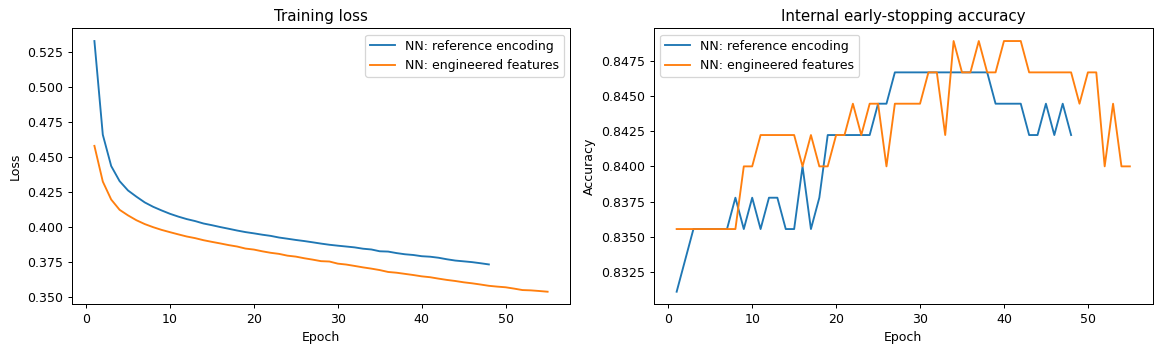

In [30]:
# Plot the full-training fit histories; internal accuracy is not the final validation score.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, model in nn_models.items():
    network = model.named_steps['model']
    axes[0].plot(range(1, len(network.loss_curve_) + 1), network.loss_curve_, label=name)
    axes[1].plot(range(1, len(network.validation_scores_) + 1),
                 network.validation_scores_, label=name)

axes[0].set(title='Training loss', xlabel='Epoch', ylabel='Loss')
axes[1].set(title='Internal early-stopping accuracy', xlabel='Epoch', ylabel='Accuracy')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()


**Reading these results:** higher AP and ROC-AUC indicate better risk ranking. Recall shows the share of leavers detected at the default threshold; precision shows how many alerts are correct. Training AP much higher than validation AP suggests overfitting. Early stopping monitors internal accuracy, so it can stop without improving minority-class detection. A falling training loss alone does not establish a useful model. Both cases retain source predictors; no test predictions are generated.

**Observed effect:** reference encoding gave mean CV AP 0.3039; engineered inputs gave 0.2559. Their validation AP values were both approximately 0.2895. Validation recall rose from 2.44% to 6.10%, but the engineered version had lower mean CV AP. Added complexity did not produce a consistent improvement in ranking. Keep both as baselines, not a final model choice.

Training AP exceeded validation AP in both cases, suggesting overfitting. These networks use one initialization seed and accuracy-based early stopping. Later experiments can test repeated seeds, regularization, and thresholds suited to minority-class detection.

**Checks:** all original predictors remain in both cases. Relative-salary medians use training data; preprocessing and feature creation are inside CV pipelines. Input counts are 39 and 42. Inputs were checked for finite values and aligned employee rows. No test predictions were generated.

### Threshold comparison and probability-average ensemble

**Purpose:** improve the useful balance between detecting leavers and generating false alerts. Compare the two existing neural networks, then average their probabilities 50/50 without fitting another model or tuning ensemble weights.

A lower threshold generally detects more leavers but generates more false alerts. AP/ROC-AUC assess risk ranking; precision, recall, F1, and alert counts assess decisions. Compare models at minimum recall targets of 20%, 40%, and 60%. These are illustrative comparison points, not agreed business requirements.

Use validation data only. Thresholds chosen here are exploratory and their scores are optimistic because this set has already informed earlier comparisons. Keep test data reserved. No earlier analyses, searches, or CV are rerun for this addition.


In [31]:
# Reuse validation predictions; average both scores with equal weights.
# Save them once so later threshold experiments can run without refitting.
from pathlib import Path
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_recall_curve, confusion_matrix,
                             precision_score, recall_score, f1_score)

validation_scores = pd.DataFrame({
    'Reference NN': nn_models['NN: reference encoding'].predict_proba(X_val)[:, 1],
    'Engineered NN': nn_models['NN: engineered features'].predict_proba(X_val)[:, 1]
}, index=y_val.index)
validation_scores['50/50 ensemble'] = validation_scores.mean(axis=1)

(PROJECT / 'artifacts/experimental_runs').mkdir(parents=True, exist_ok=True)
np.savez(PROJECT / 'artifacts/experimental_runs/nn_validation_scores.npz',
         scores=validation_scores.to_numpy(), columns=validation_scores.columns.to_numpy(dtype=str),
         target=y_val.to_numpy(), row_index=y_val.index.to_numpy())

# AP and ROC-AUC measure ranking and do not depend on a classification threshold.
ranking_comparison = pd.DataFrame({
    name: {'AP': average_precision_score(y_val, values),
           'ROC-AUC': roc_auc_score(y_val, values)}
    for name, values in validation_scores.items()
}).T
display(ranking_comparison.round(4))


,AP,ROC-AUC
Reference NN,0.2895,0.6791
Engineered NN,0.2895,0.6904
50/50 ensemble,0.2964,0.6872


In [32]:
# Compare detection and false alerts at several thresholds.
def threshold_metrics(name, threshold):
    prediction = (validation_scores[name] >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, prediction, labels=[0, 1]).ravel()
    return {
        'Model': name, 'Threshold': threshold,
        'Precision': precision_score(y_val, prediction, zero_division=0),
        'Recall': recall_score(y_val, prediction, zero_division=0),
        'F1': f1_score(y_val, prediction, zero_division=0),
        'Alerts': int(tp + fp), 'False alerts': int(fp), 'Missed leavers': int(fn)
    }

threshold_comparison = pd.DataFrame([
    threshold_metrics(name, threshold)
    for name in validation_scores
    for threshold in [0.50, 0.40, 0.30, 0.20, 0.10]
])
display(threshold_comparison.round(4))


,Model,Threshold,Precision,Recall,F1,Alerts,False alerts,Missed leavers
0,Reference NN,0.5,0.2667,0.0244,0.0447,15,11,160
1,Reference NN,0.4,0.3636,0.1220,0.1826,55,35,144
2,Reference NN,0.3,0.3237,0.2744,0.2970,139,94,119
3,Reference NN,0.2,0.2875,0.5488,0.3774,313,223,74
4,Reference NN,0.1,0.2128,0.8110,0.3371,625,492,31
5,Engineered NN,0.5,0.3704,0.0610,0.1047,27,17,154
6,Engineered NN,0.4,0.3750,0.1463,0.2105,64,40,140
7,Engineered NN,0.3,0.3179,0.2927,0.3048,151,103,116
8,Engineered NN,0.2,0.2697,0.5427,0.3603,330,241,75
9,Engineered NN,0.1,0.2189,0.7927,0.3430,594,464,34


In [33]:
# Compare models at similar recall, rather than assuming 0.5 is equally suitable.
# Use the highest threshold that reaches each minimum recall target.
matched_rows = []
for target_recall in [0.20, 0.40, 0.60]:
    for name in validation_scores:
        precision, recall, thresholds = precision_recall_curve(y_val, validation_scores[name])
        valid = np.where(recall[:-1] >= target_recall)[0]
        threshold = thresholds[valid[-1]]
        row = threshold_metrics(name, threshold)
        row['Minimum recall'] = target_recall
        matched_rows.append(row)

matched_recall_comparison = pd.DataFrame(matched_rows)
display(matched_recall_comparison[
    ['Minimum recall', 'Model', 'Threshold', 'Precision', 'Recall',
     'F1', 'Alerts', 'False alerts', 'Missed leavers']
].round(4))


,Minimum recall,Model,Threshold,Precision,Recall,F1,Alerts,False alerts,Missed leavers
0,0.2,Reference NN,0.3399,0.3474,0.2012,0.2548,95,62,131
1,0.2,Engineered NN,0.3656,0.3929,0.2012,0.2661,84,51,131
2,0.2,50/50 ensemble,0.3382,0.3402,0.2012,0.2529,97,64,131
3,0.4,Reference NN,0.2440,0.2857,0.4024,0.3342,231,165,98
4,0.4,Engineered NN,0.2480,0.2960,0.4024,0.3411,223,157,98
5,0.4,50/50 ensemble,0.2477,0.2933,0.4024,0.3393,225,159,98
6,0.6,Reference NN,0.1775,0.2640,0.6037,0.3673,375,276,65
7,0.6,Engineered NN,0.1818,0.2676,0.6037,0.3708,370,271,65
8,0.6,50/50 ensemble,0.1781,0.2578,0.6037,0.3613,384,285,65


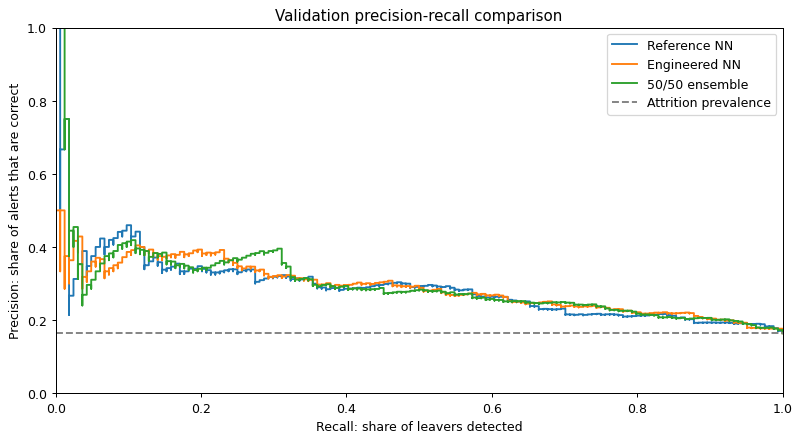

In [34]:
# Visualize the precision-recall trade-off across all possible thresholds.
plt.figure(figsize=(9, 5))
for name in validation_scores:
    precision, recall, _ = precision_recall_curve(y_val, validation_scores[name])
    plt.step(recall, precision, where='post', label=name)
plt.axhline(y_val.mean(), linestyle='--', color='grey', label='Attrition prevalence')
plt.xlabel('Recall: share of leavers detected')
plt.ylabel('Precision: share of alerts that are correct')
plt.title('Validation precision-recall comparison')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()


**Interpretation:** compare rows at the same recall target. Higher precision means fewer false alerts for a similar number of detected leavers. Lowering a threshold changes decisions; it does not improve AP or ROC-AUC.

At 20% minimum recall, the reference model generated 62 false alerts versus 64 for the ensemble; precision was 34.7% versus 34.0%.
At 40% minimum recall, the reference model generated 165 false alerts versus 159 for the ensemble; precision was 28.6% versus 29.3%.
At 60% minimum recall, the reference model generated 276 false alerts versus 285 for the ensemble; precision was 26.4% versus 25.8%.

**Decision:** do not select an ensemble simply because one ranking score increases. Choose an operating recall/alert budget first, then compare precision and false alerts there. Any preferred candidate needs stability checks before final test evaluation. No final threshold or replacement model is adopted automatically.

**Useful candidate at threshold 0.30:** the reference NN detected 45 leavers with 94 false alerts (precision 32.4%, recall 27.4%). The equal-weight ensemble detected 51 with 90 false alerts (precision 36.2%, recall 31.1%). This is a better validation trade-off at that operating point, not merely a higher AP.

**No universal winner:** at matched 20%, 40%, and 60% recall, the engineered NN produced fewer false alerts than the ensemble. The ensemble's AP was 0.2964 versus about 0.2895 for either NN, but it did not dominate the full precision-recall curve. Keep the 0.30 ensemble as an exploratory candidate only if roughly 31% recall and 141 alerts per 1,000 employees meet the intended operating needs. A final choice needs an agreed recall/alert budget and stability checks; the engineered NN previously had weaker CV AP. Test data remains reserved.

### Model-family shortlist for focused tuning

**Select logistic regression and the neural network with original predictors.** This is a shortlist for tuning, not a final model choice.

- Logistic regression has the strongest baseline CV and validation average precision, with a simple model structure.
- The original-feature NN has baseline CV AP similar to random forest (0.3039 versus 0.3070), with higher validation AP (0.2895 versus 0.2510). Its previous training/validation gap means regularization and architecture need attention.
- Keep random forest as a benchmark: it had slightly higher baseline CV AP and lower fold variability than the NN. Its previous tuning improved validation AP to 0.266, which remains below the NN baseline. This does not prove the NN is superior; CV differences are small and validation has been reused.
- Decision tree ranked substantially below the alternatives. The dummy remains a reference for trivial predictions. The engineered NN had weaker CV AP. Its ensemble remains an optional later candidate, rather than a separate modeling technique with established CV evidence.

The table reports historical baseline scores, not selected grid-search CV scores. Initial logistic/tree baselines used full one-hot encoding, while the NN used reference encoding; the separate L2 reference-encoding check produced nearly identical logistic scores. For the next tuning round, use all 25 original predictors with reference-category encoding and scaling (39 inputs) for both selected families. Keep reduced/engineered versions as experiments, not defaults.


In [35]:
# Compare existing baseline results without fitting models again.
baseline_family_comparison = pd.DataFrame({
    'CV AP': cv_comparison['AP'],
    'CV AP std': cv_comparison['AP std'],
    'Validation AP': validation_comparison['AP'],
    'Validation ROC-AUC': validation_comparison['ROC_AUC']
})

for name, row in nn_comparison.iterrows():
    baseline_family_comparison.loc[name] = [
        row['CV AP'], row['CV AP std'], row['Validation AP'], row['ROC-AUC']
    ]

selected_baseline_families = ['Logistic regression', 'NN: reference encoding']
baseline_family_comparison['Selected for tuning'] = (
    baseline_family_comparison.index.isin(selected_baseline_families)
)
display(baseline_family_comparison.sort_values('Validation AP', ascending=False).round(4))


,CV AP,CV AP std,Validation AP,Validation ROC-AUC,Selected for tuning
Model,,,,,
Logistic regression,0.3258,0.0398,0.2921,0.6933,True
NN: engineered features,0.2559,0.0567,0.2895,0.6904,False
NN: reference encoding,0.3039,0.0402,0.2895,0.6791,True
Random forest,0.3074,0.0268,0.2509,0.6594,False
Decision tree,0.1793,0.0124,0.1755,0.5321,False
Dummy,0.1633,0.0000,0.1640,0.5000,False


**Next tuning round:** use the same five stratified training folds and select by average precision. For logistic regression, refine regularization and class weighting around the earlier results. For the NN, try a small set of hidden-layer sizes, L2 strengths, and learning rates, and review its accuracy-based early-stopping limitation. Compare validation precision/recall at matched operating targets after tuning. No new fitting, threshold selection, or test evaluation was performed for this shortlist.

### Focused tuning: logistic regression and a small neural network

Tune each family separately using all original predictors, reference-category encoding, and scaling. Keep the existing 60/20/20 split. Each candidate fits its preprocessing inside the same five stratified training folds. Earlier EDA, searches, and models are not rerun.

**Bound the effort:** try 24 LR settings and 12 NN settings. The NN has only one hidden layer with 8 or 16 neurons and a 300-epoch cap. Compare early stopping based on internal accuracy against stopping when training loss stops improving. These are limited experiments, not an exhaustive optimum.

**Trade-off rule:** keep the highest CV AP and an economical alternative within 0.005 absolute AP. For the NN favor fewer neurons, then faster CV fitting; for LR favor faster CV fitting. This tolerance is practical, not a significance test. Do not use validation scores to choose the search winner.

Record search wall/CPU time, final fit time, median prediction time for 1,000 validation rows, and parameter counts. One worker and one math-library thread limit resource use. Timing is approximate; search totals reflect different trial counts. Actual electrical energy is not measured, and runtime/model size are only indicators of computational cost. Convergence-warning counts are reported rather than hidden; an epoch cap can stop an incompletely converged model. Test data remains reserved.


**Repeat-run safeguard:** the economical alternatives selected and reviewed in the original run are recorded in artifacts/reviewed_economical_parameters.json. Reuse those settings, refit them and measure their current cost. They must still be within 0.005 AP of the current CV winner; otherwise stop for review. This prevents timing noise from silently changing the compared alternatives. CV-winner selection and frozen final models/thresholds are unchanged.

In [36]:
# Keep the same folds, inputs, and scoring for both tuning exercises.
import time
import warnings
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

focused_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
focused_scoring = {
    'AP': 'average_precision', 'ROC_AUC': 'roc_auc',
    'Precision': make_scorer(precision_score, zero_division=0),
    'Recall': make_scorer(recall_score, zero_division=0),
    'F1': make_scorer(f1_score, zero_division=0)
}
focused_search_cost = []


In [37]:
# Logistic regression: refine regularization and class weights around earlier results.
focused_lr_pipeline = Pipeline([
    ('preprocess', make_reference_preprocessor(True)),
    ('model', LogisticRegression(solver='saga', max_iter=5000, random_state=42))
])
focused_lr_grid = [
    {'model__penalty': ['l1', 'l2'], 'model__C': [0.03, 0.1, 0.3],
     'model__class_weight': [None, 'balanced']},
    {'model__penalty': ['elasticnet'], 'model__C': [0.03, 0.1, 0.3],
     'model__l1_ratio': [0.25, 0.75], 'model__class_weight': [None, 'balanced']}
]
focused_lr_search = GridSearchCV(
    focused_lr_pipeline, focused_lr_grid, cv=focused_cv,
    scoring=focused_scoring, refit='AP', n_jobs=1, error_score='raise'
)
wall_start, cpu_start = time.perf_counter(), time.process_time()
with warnings.catch_warnings(record=True) as lr_warnings:
    warnings.simplefilter('always')
    focused_lr_search.fit(X_train, y_train)
focused_search_cost.append({
    'Model': 'Logistic regression', 'Configurations': 24,
    'Wall seconds': time.perf_counter() - wall_start,
    'CPU seconds': time.process_time() - cpu_start,
    'Convergence warnings': sum(issubclass(w.category, ConvergenceWarning) for w in lr_warnings)
})
print('Best LR parameters:', focused_lr_search.best_params_)
print('Best LR CV AP:', round(focused_lr_search.best_score_, 4))
print('LR convergence warnings:', focused_search_cost[-1]['Convergence warnings'])


Best LR parameters: {'model__C': 0.1, 'model__class_weight': None, 'model__l1_ratio': 0.25, 'model__penalty': 'elasticnet'}
Best LR CV AP: 0.3308
LR convergence warnings: 0


In [38]:
# Neural network: only one hidden layer, with 8 or 16 neurons.
# Compare accuracy-based early stopping with stopping based on training-loss progress.
focused_nn_pipeline = Pipeline([
    ('preprocess', make_reference_preprocessor(True)),
    ('model', MLPClassifier(
        activation='relu', solver='adam', batch_size=64, max_iter=300,
        validation_fraction=0.15, tol=0.001, random_state=42
    ))
])
focused_nn_grid = [
    {'model__hidden_layer_sizes': [(8,), (16,)], 'model__alpha': [0.01, 0.1],
     'model__learning_rate_init': [0.001], 'model__early_stopping': [True],
     'model__n_iter_no_change': [20]},
    {'model__hidden_layer_sizes': [(8,), (16,)], 'model__alpha': [0.1, 1.0],
     'model__learning_rate_init': [0.0005], 'model__early_stopping': [True],
     'model__n_iter_no_change': [20]},
    {'model__hidden_layer_sizes': [(8,), (16,)], 'model__alpha': [0.1, 1.0],
     'model__learning_rate_init': [0.001], 'model__early_stopping': [False],
     'model__n_iter_no_change': [10]}
]
focused_nn_search = GridSearchCV(
    focused_nn_pipeline, focused_nn_grid, cv=focused_cv,
    scoring=focused_scoring, refit='AP', n_jobs=1, error_score='raise'
)
wall_start, cpu_start = time.perf_counter(), time.process_time()
with warnings.catch_warnings(record=True) as nn_warnings:
    warnings.simplefilter('always')
    focused_nn_search.fit(X_train, y_train)
focused_search_cost.append({
    'Model': 'Neural network', 'Configurations': 12,
    'Wall seconds': time.perf_counter() - wall_start,
    'CPU seconds': time.process_time() - cpu_start,
    'Convergence warnings': sum(issubclass(w.category, ConvergenceWarning) for w in nn_warnings)
})
print('Best NN parameters:', focused_nn_search.best_params_)
print('Best NN CV AP:', round(focused_nn_search.best_score_, 4))
print('NN convergence warnings:', focused_search_cost[-1]['Convergence warnings'])
display(pd.DataFrame(focused_search_cost).set_index('Model').round(3))


Best NN parameters: {'model__alpha': 1.0, 'model__early_stopping': False, 'model__hidden_layer_sizes': (16,), 'model__learning_rate_init': 0.001, 'model__n_iter_no_change': 10}
Best NN CV AP: 0.3202
NN convergence warnings: 0


,Configurations,Wall seconds,CPU seconds,Convergence warnings
Model,,,,
Logistic regression,24,33.680,33.938,0
Neural network,12,37.993,38.047,0


In [39]:
# Keep the CV winner and an economical near-best option for each family.
# An absolute AP tolerance of 0.005 is a practical rule, not statistical significance.
reviewed_economical_parameters = json.loads(
    (PROJECT / 'artifacts/reviewed_economical_parameters.json').read_text(encoding='utf-8'))
focused_models = {}
focused_rows = []
focused_probabilities = pd.DataFrame(index=y_val.index)
focused_parameters = {}
for family, search in [('LR', focused_lr_search), ('NN', focused_nn_search)]:
    results = pd.DataFrame(search.cv_results_)
    near_best = results[results['mean_test_AP'] >= search.best_score_ - 0.005].copy()
    # Keep reviewed alternatives reproducible; measured fit times fluctuate.
    reviewed = reviewed_economical_parameters[family]
    matches = near_best['params'].apply(
        lambda params: json.dumps(params, sort_keys=True) == json.dumps(reviewed, sort_keys=True))
    assert matches.any(), 'Reviewed alternative no longer meets the CV tolerance; review on training/validation only.'
    economical_index = near_best.index[matches][0]

    options = [('CV best', search.best_index_)]
    if economical_index != search.best_index_:
        options.append(('Economical', economical_index))
    for option, index in options:
        name = family + ': ' + option
        parameters = results.loc[index, 'params']
        model = clone(search.estimator).set_params(**parameters)
        fit_start = time.perf_counter()
        model.fit(X_train, y_train)
        fit_seconds = time.perf_counter() - fit_start
        focused_models[name] = model
        focused_parameters[name] = parameters
        probability = model.predict_proba(X_val)[:, 1]
        prediction = model.predict(X_val)
        focused_probabilities[name] = probability

        # Warm predictions, then report the median of five timed validation batches.
        latency = []
        for repeat in range(5):
            predict_start = time.perf_counter()
            model.predict_proba(X_val)
            latency.append(1000 * (time.perf_counter() - predict_start))
        estimator = model.named_steps['model']
        if family == 'NN':
            parameters_count = sum(a.size for a in estimator.coefs_ + estimator.intercepts_)
        else:
            parameters_count = estimator.coef_.size + estimator.intercept_.size
        focused_rows.append({
            'Candidate': name,
            'CV AP': results.loc[index, 'mean_test_AP'],
            'CV AP std': results.loc[index, 'std_test_AP'],
            'Validation AP': average_precision_score(y_val, probability),
            'ROC-AUC': roc_auc_score(y_val, probability),
            'Precision': precision_score(y_val, prediction, zero_division=0),
            'Recall': recall_score(y_val, prediction, zero_division=0),
            'F1': f1_score(y_val, prediction, zero_division=0),
            'Training AP': average_precision_score(y_train, model.predict_proba(X_train)[:, 1]),
            'Final fit seconds': fit_seconds,
            'Predict ms/1000': np.median(latency),
            'Parameters': parameters_count,
            'Iterations': estimator.n_iter_ if family == 'NN' else int(estimator.n_iter_[0])
        })

focused_comparison = pd.DataFrame(focused_rows).set_index('Candidate')
display(focused_comparison.round(4))
for name, parameters in focused_parameters.items():
    print(name, parameters)


LR: CV best {'model__C': 0.1, 'model__class_weight': None, 'model__l1_ratio': 0.25, 'model__penalty': 'elasticnet'}
LR: Economical {'model__C': 0.03, 'model__class_weight': 'balanced', 'model__l1_ratio': 0.25, 'model__penalty': 'elasticnet'}
NN: CV best {'model__alpha': 1.0, 'model__early_stopping': False, 'model__hidden_layer_sizes': (16,), 'model__learning_rate_init': 0.001, 'model__n_iter_no_change': 10}
NN: Economical {'model__alpha': 1.0, 'model__early_stopping': False, 'model__hidden_layer_sizes': (8,), 'model__learning_rate_init': 0.001, 'model__n_iter_no_change': 10}


,CV AP,CV AP std,Validation AP,ROC-AUC,Precision,Recall,F1,Training AP,Final fit seconds,Predict ms/1000,Parameters,Iterations
Candidate,,,,,,,,,,,,
LR: CV best,0.3308,0.0417,0.2973,0.6986,0.200,0.0122,0.0230,0.3466,0.1392,34.3517,40,32
LR: Economical,0.3267,0.0391,0.2974,0.6993,0.262,0.6341,0.3708,0.3378,0.1272,32.2604,40,17
NN: CV best,0.3202,0.0389,0.2936,0.6969,0.000,0.0000,0.0000,0.3698,0.6317,31.6603,657,33
NN: Economical,0.3184,0.0301,0.3000,0.6929,0.000,0.0000,0.0000,0.3508,0.6618,31.7395,329,35


In [40]:
# Compare false alerts at similar recall before deciding whether extra cost is worthwhile.
focused_operating_rows = []
for recall_target in [0.40, 0.60]:
    for name, probability in focused_probabilities.items():
        precision, recall, thresholds = precision_recall_curve(y_val, probability)
        valid = np.where(recall[:-1] >= recall_target)[0]
        threshold = thresholds[valid[-1]]
        prediction = (probability >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_val, prediction, labels=[0, 1]).ravel()
        focused_operating_rows.append({
            'Recall target': recall_target, 'Candidate': name, 'Threshold': threshold,
            'Precision': precision_score(y_val, prediction, zero_division=0),
            'Recall': recall_score(y_val, prediction, zero_division=0),
            'Detected leavers': int(tp), 'False alerts': int(fp), 'Missed leavers': int(fn)
        })
focused_operating_comparison = pd.DataFrame(focused_operating_rows)
display(focused_operating_comparison.round(4))

# Cache fitted pipelines and validation scores to avoid refitting in later comparisons.
import joblib
from pathlib import Path
(PROJECT / 'artifacts/experimental_runs').mkdir(parents=True, exist_ok=True)
joblib.dump(focused_models, PROJECT / 'artifacts/experimental_runs/focused_tuned_models.joblib')
np.savez(PROJECT / 'artifacts/experimental_runs/focused_tuning_scores.npz',
         scores=focused_probabilities.to_numpy(),
         columns=focused_probabilities.columns.to_numpy(dtype=str),
         target=y_val.to_numpy(), row_index=y_val.index.to_numpy())


,Recall target,Candidate,Threshold,Precision,Recall,Detected leavers,False alerts,Missed leavers
0,0.4,LR: CV best,0.2404,0.3188,0.4024,66,141,98
1,0.4,LR: Economical,0.6099,0.3128,0.4024,66,145,98
2,0.4,NN: CV best,0.2471,0.3084,0.4024,66,148,98
3,0.4,NN: Economical,0.2473,0.3173,0.4024,66,142,98
4,0.6,LR: CV best,0.1699,0.2654,0.6037,99,274,65
5,0.6,LR: Economical,0.5106,0.2612,0.6037,99,280,65
6,0.6,NN: CV best,0.1929,0.2727,0.6037,99,264,65
7,0.6,NN: Economical,0.1878,0.2712,0.6037,99,266,65


**Interpretation:** compare AP and ROC-AUC for ranking, then precision and false alerts at the same recall target for practical usefulness. Default-threshold recall can change simply because class weighting shifts the score scale. CV winners are selected from many trials, so their CV scores are optimistic; validation has also been reused. No candidate is automatically finalized.

LR CV winner: CV AP 0.3308, validation AP 0.2973, fit 0.116s, prediction 12.187ms per 1,000 rows, 40 parameters.
NN CV winner: CV AP 0.3202, validation AP 0.2936, fit 0.550s, prediction 13.547ms per 1,000 rows, 657 parameters.

**Energy and stopping:** wall/CPU times and parameter counts are measured here, but no electricity consumption is measured. Accuracy-based early stopping may favor the majority class. Training-loss stopping can use more epochs and overfit; inspect the training/validation AP gap, iterations, and warning counts. Small timing differences may be measurement noise.

**Status:** both families have been tuned separately within a limited budget. Review the economical options and matched-recall table before choosing a final model, threshold, or spending more compute. Fitted pipelines and validation scores are cached for later comparisons.

**Trade-off observed:** within the NN family, 8 neurons gave CV AP 0.3184 versus 0.3202 for 16 neurons, with 329 rather than 657 parameters. Validation AP was 0.3000 versus 0.2936. This supports carrying the smaller NN forward as a challenger. Its measured fit time was only slightly lower (0.531s versus 0.550s), so halving parameters did not halve runtime.

**Compare with LR:** the best LR had CV AP 0.3308, validation AP 0.2973, and a 0.116s final fit. At roughly 40% recall, LR generated 141 false alerts and the smaller NN 142. At roughly 60% recall, LR generated 274 versus 266 for the smaller NN. The NN's extra cost buys a small validation benefit at the higher-recall point, not a clear overall win. Prediction times were close (about 12.2ms versus 14.8ms per 1,000 rows) and may vary between runs. No electrical-energy measurements were made.

**Important threshold finding:** both tuned NNs predicted no leavers at 0.5, giving zero recall/F1 there. Their risk ranking remains useful, but they require an operating threshold suited to this imbalanced task. Balanced LR increased default-threshold recall, yet its ranking and matched-recall results were weaker than the CV-winning LR. A higher recall at 0.5 alone is therefore not proof of improvement.

**Next review:** carry the best-CV LR and the economical 8-neuron NN forward for the performance/cost decision. This is a shortlist, not a final winner. Agree on the required recall or alert budget and assess stability before freezing a threshold and performing final test evaluation. No more layers, broad searches, or automatic model replacement are justified by these small differences yet.

### Criteria for selecting the final model

Attrition is the minority class. Predicting that everyone stays would already give about 84% accuracy, so accuracy is not our main criterion.

| Criterion | Why it matters | How we use it |
|---|---|---|
| Recall | Share of actual leavers detected | Agree on the minimum useful detection rate, rather than maximize it without limit. |
| Precision and false-alert count | Whether alerts are actionable and affordable | At the same recall target, prefer higher precision and fewer false alerts. |
| Average precision (AP) | Summarizes precision-recall ranking across thresholds | Main training-CV tuning score; compare validation AP as supporting evidence. |
| Stability | Whether gains persist across folds or NN seeds | Avoid deciding from one favorable split or a tiny difference. The NN results currently use one seed. |
| F1 / F-beta | Summarizes a chosen precision-recall balance | F1 weights both equally. Use a different beta only if business priorities justify it. |
| ROC-AUC | Overall discrimination | Supporting measure; it does not establish that the alert workload is acceptable. |
| Runtime and complexity | Cost of obtaining and maintaining predictions | Prefer the simpler/faster model when practical predictive performance is similar. Actual electricity was not measured. |

**Decision rule:** first agree on a minimum recall or a maximum number of alerts. Compare precision, missed leavers, and false alerts at that operating point, then check AP and stability. If performance is effectively similar, favor the simpler, cheaper model. If credible costs of missed leavers and false alerts are available, compare their combined cost rather than assuming the errors are equally costly.

**Current evidence:** LR has higher mean CV AP (0.3308 versus 0.3184 for the 8-neuron NN), while the NN has slightly higher validation AP (0.3000 versus 0.2973). These small differences do not prove superiority. At about 40% recall, LR and NN have 141 and 142 false alerts respectively, favoring the simpler LR. At about 60% recall, the NN has 266 false alerts versus LR's 274, which could justify the NN if that small gain is stable and operationally valuable. The 40%/60% targets are examples, not agreed requirements.

**Provisional preference:** LR when the practical trade-off is similar; retain the smaller NN as a challenger for higher-recall operation. Freeze the model and threshold using training/validation evidence, then evaluate the selected model once on the reserved test set. Repeated validation use makes these exploratory comparisons optimistic. Test results should verify the choice, not start another tuning cycle.


## Full execution check
All four project notebooks completed in fresh processes: 96 code cells, no remaining execution errors. The original model/feature metrics match within their saved display precision, and all reviewed candidates reproduce their original validation probabilities within floating-point precision.

Two issues were corrected: skip identical CSV rewrites after a transient catalog access error; retain reviewed economical settings because fastest-fit rankings vary between runs. Economical settings still must meet the same 0.005 AP tolerance. Original splits, preprocessing, search grids, CV winners and frozen test policies are preserved.

The original notebook and protected model/score artifacts remain unchanged. The freshly refitted final candidates also reproduce the original test probabilities. No new test-based tuning was performed. Details are in EXECUTION_CHECK.md and artifacts/execution_audit.
